# Apple Stock Price Prediction

## EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
df=pd.read_csv('P721 DATASET.csv')

In [4]:
# Convert Date column into datetime format
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Remove invalid dates
df.dropna(subset=['Date'], inplace=True)

# Remove duplicate dates
df.drop_duplicates(subset=['Date'], inplace=True)

# Set Date as index
df.set_index('Date', inplace=True)

# Sort data chronologically
df.sort_index(inplace=True)

In [5]:
print("Dataset Shape:",df.shape)
print("\nFirst 5 rows")
df.head()

Dataset Shape: (2011, 6)

First 5 rows


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


In [6]:
print('Last Five Records')
df.tail()

Last Five Records


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2019-12-23,280.529999,284.250000,280.369995,284.000000,282.054138,24643000
2019-12-24,284.690002,284.890015,282.920013,284.269989,282.322266,12119700
2019-12-26,284.820007,289.980011,284.700012,289.910004,287.923645,23280300
2019-12-27,291.119995,293.970001,288.119995,289.799988,287.814392,36566500
2019-12-30,289.459991,292.690002,285.220001,291.519989,289.522614,36028600


In [7]:
print('Random samples')
display(df.sample(min(5,len(df)),random_state=42))

Random samples


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2017-03-29,143.679993,144.490005,143.190002,144.119995,137.322098,29190000
2014-02-06,72.865715,73.357140,72.544289,73.215714,65.825577,64441300
2013-07-29,62.971428,64.284286,62.885715,63.970001,56.466217,62014400
2017-08-03,157.050003,157.210007,155.020004,155.570007,148.843903,27097300
2013-09-24,70.697144,70.781425,69.688568,69.871429,62.082623,91086100


In [8]:
# Dataset Inforamtion
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2011 entries, 2012-01-03 to 2019-12-30
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       2011 non-null   float64
 1   High       2011 non-null   float64
 2   Low        2011 non-null   float64
 3   Close      2011 non-null   float64
 4   Adj Close  2011 non-null   float64
 5   Volume     2011 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 110.0 KB


In [9]:
# Descriptive Statistics
df.describe()

,Open,High,Low,Close,Adj Close,Volume
count,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2.011000e+03
mean,126.707469,127.827594,125.580258,126.741235,119.505548,5.949670e+07
std,50.483753,50.926301,50.124940,50.578369,52.438444,4.683856e+07
min,55.424286,57.085712,55.014286,55.790001,48.921928,1.136200e+07
25%,85.882858,86.717858,85.056427,86.202145,75.056679,2.758565e+07
50%,113.050003,114.190002,111.870003,113.050003,105.222908,4.346900e+07
75%,165.190002,167.409996,163.424995,165.245002,160.047111,7.471030e+07
max,291.119995,293.970001,288.119995,291.519989,289.522614,3.765300e+08


### Data Quality and Consistency

In [10]:
print('Missing Values')
df.isnull().sum()

Missing Values


Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [11]:
# Duplicate Rows
print("Total Duplicate Rows")
df.duplicated().sum()

Total Duplicate Rows


np.int64(0)

In [12]:
numeric_cols=df.select_dtypes(include=np.number).columns
numeric_cols

Index(['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')

In [13]:
print('Zer or Negtive Values')
print((df[numeric_cols]<=0).sum())

Zer or Negtive Values
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64


In [14]:
print("OHLC Consistency Check")
print("High Below Low:",
      (df["High"] < df["Low"]).sum())
print("High Below Open or Close:",
      (df["High"] < df[["Open", "Close"]].max(axis=1)).sum())
print("Low Above Open or Close:",
      (df["Low"] > df[["Open", "Close"]].min(axis=1)).sum())

OHLC Consistency Check
High Below Low: 0
High Below Open or Close: 0
Low Above Open or Close: 0


### Numerical Descriptive analysis

In [15]:
numeric_cols=df.select_dtypes(include=np.number).columns

In [16]:
statistics=pd.DataFrame({
    'Mean':df[numeric_cols].mean(),
    'Median': df[numeric_cols].median(),
    'Mode':df[numeric_cols].mode().iloc[0],
    'Standard deviation': df[numeric_cols].std(),
    'Minimum': df[numeric_cols].min(),
    'Maximum': df[numeric_cols].max(),
    'Skewness':df[numeric_cols].skew()
})
display(statistics.round(3))

,Mean,Median,Mode,Standard deviation,Minimum,Maximum,Skewness
Open,1.267070e+02,1.130500e+02,7.500000e+01,5.048400e+01,5.542400e+01,2.911200e+02,0.769
High,1.278280e+02,1.141900e+02,9.570000e+01,5.092600e+01,5.708600e+01,2.939700e+02,0.771
Low,1.255800e+02,1.118700e+02,9.410000e+01,5.012500e+01,5.501400e+01,2.881200e+02,0.771
Close,1.267410e+02,1.130500e+02,9.734000e+01,5.057800e+01,5.579000e+01,2.915200e+02,0.774
Adj Close,1.195060e+02,1.052230e+02,5.663200e+01,5.243800e+01,4.892200e+01,2.895230e+02,0.794
Volume,5.949670e+07,4.346900e+07,2.435840e+07,4.683856e+07,1.136200e+07,3.765300e+08,2.165


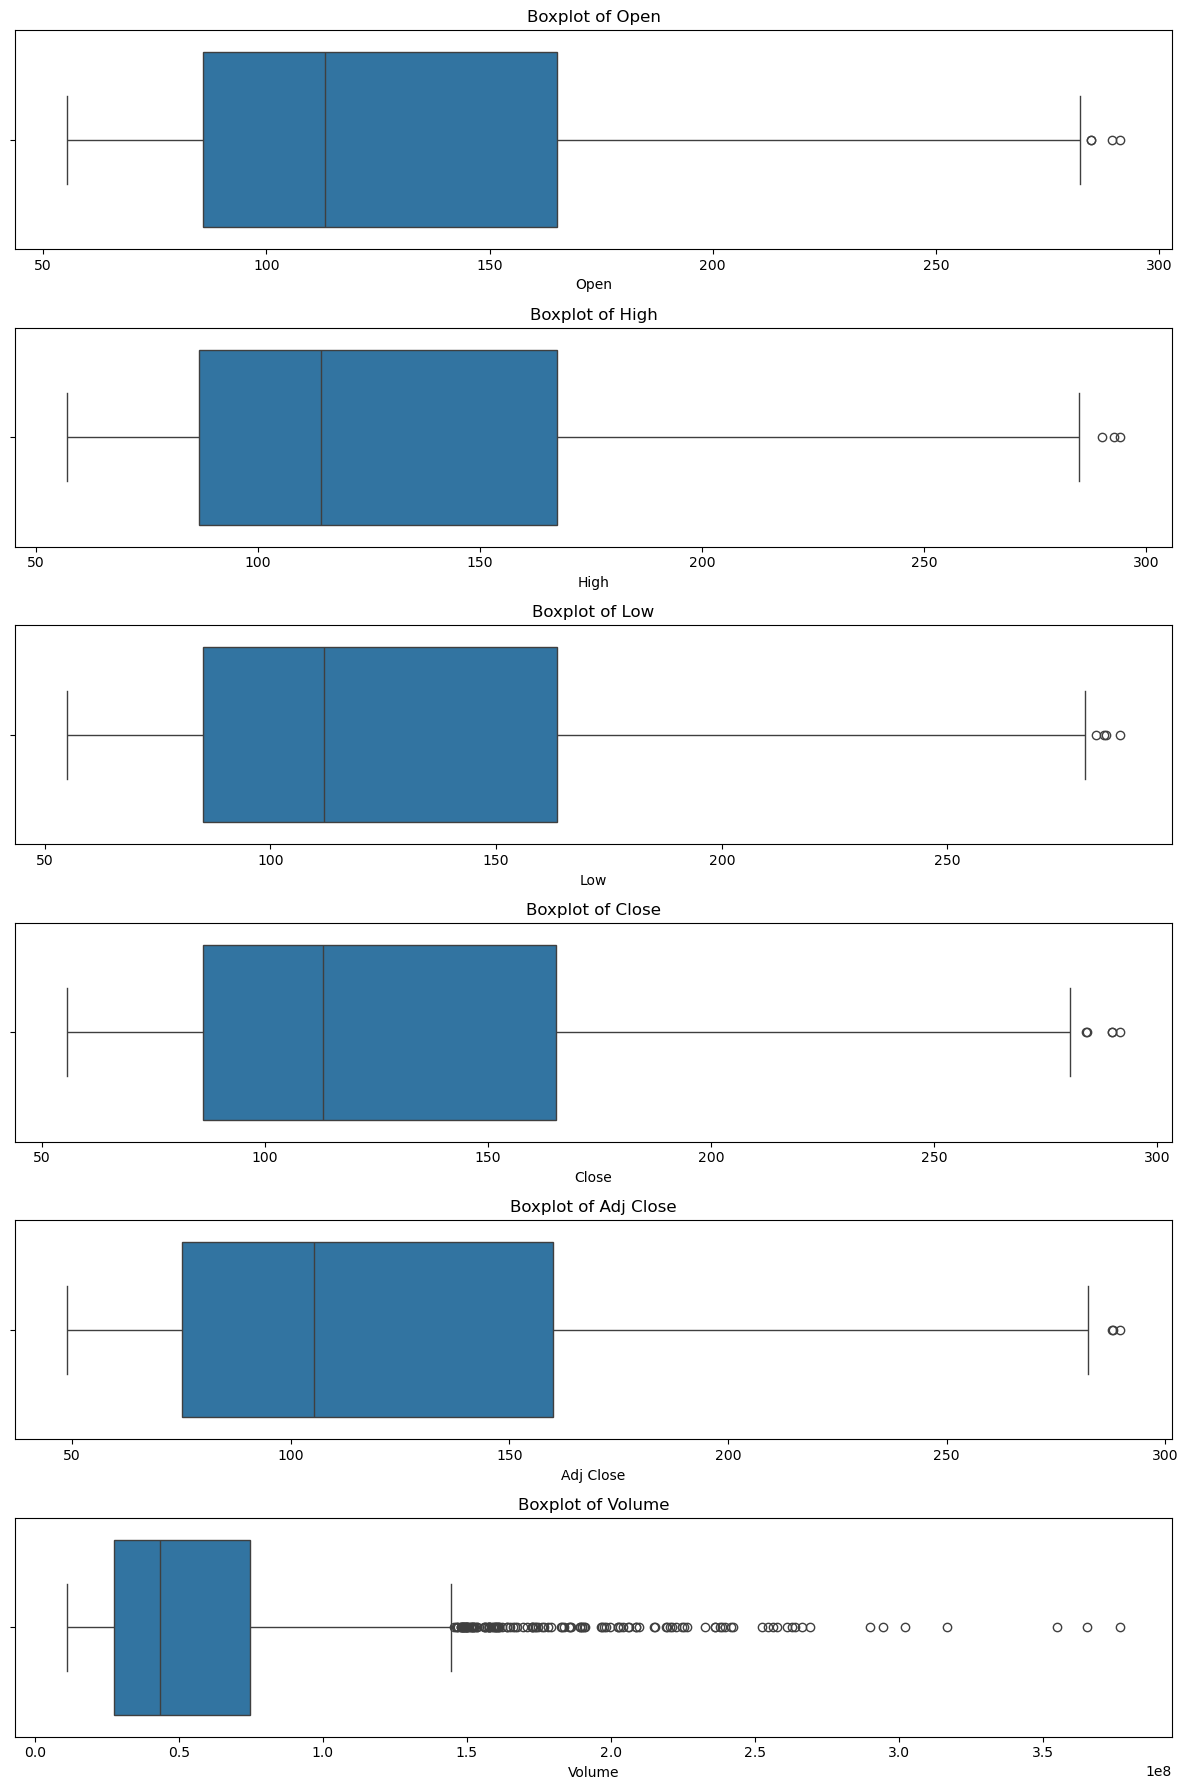

IQR Outlier Summary
Open:4 potential outliers(lower=-33.08,upper=284.15)
High:3 potential outliers(lower=-34.32,upper=288.45)
Low:4 potential outliers(lower=-32.50,upper=280.98)
Close:5 potential outliers(lower=-32.36,upper=283.81)
Adj Close:3 potential outliers(lower=-52.43,upper=287.53)
Volume:127 potential outliers(lower=-43101325.00,upper=145397275.00)


In [17]:
numeric_cols=df.select_dtypes(include=np.number).columns
fig,axes=plt.subplots(nrows=len(numeric_cols),ncols=1,figsize=(12,3*len(numeric_cols)))
for ax,col in zip(axes,numeric_cols):
    sns.boxplot(x=df[col],ax=ax)
    ax.set_title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

print('IQR Outlier Summary')

for col in numeric_cols:
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    IQR=q3-q1

    lower=q1-1.5*IQR
    upper=q3+1.5*IQR
    count=((df[col]<lower)|(df[col]>upper)).sum()
    print(
        f'{col}:{count} potential outliers'
        f'(lower={lower:.2f},upper={upper:.2f})'
)

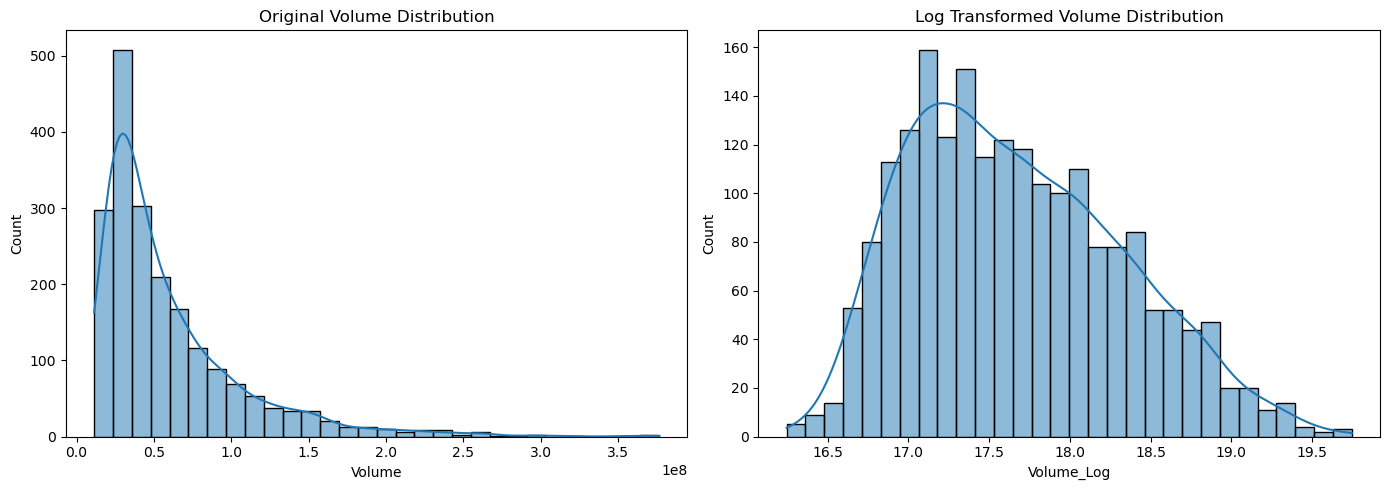

In [18]:
# Handling Volume Skewness using log Transformation
df["Volume_Log"] = np.log1p(df["Volume"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["Volume"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Original Volume Distribution")
sns.histplot(df["Volume_Log"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Log Transformed Volume Distribution")
plt.tight_layout()
plt.show()

# Visualizations

### Apple Stock Closing Price Visualization

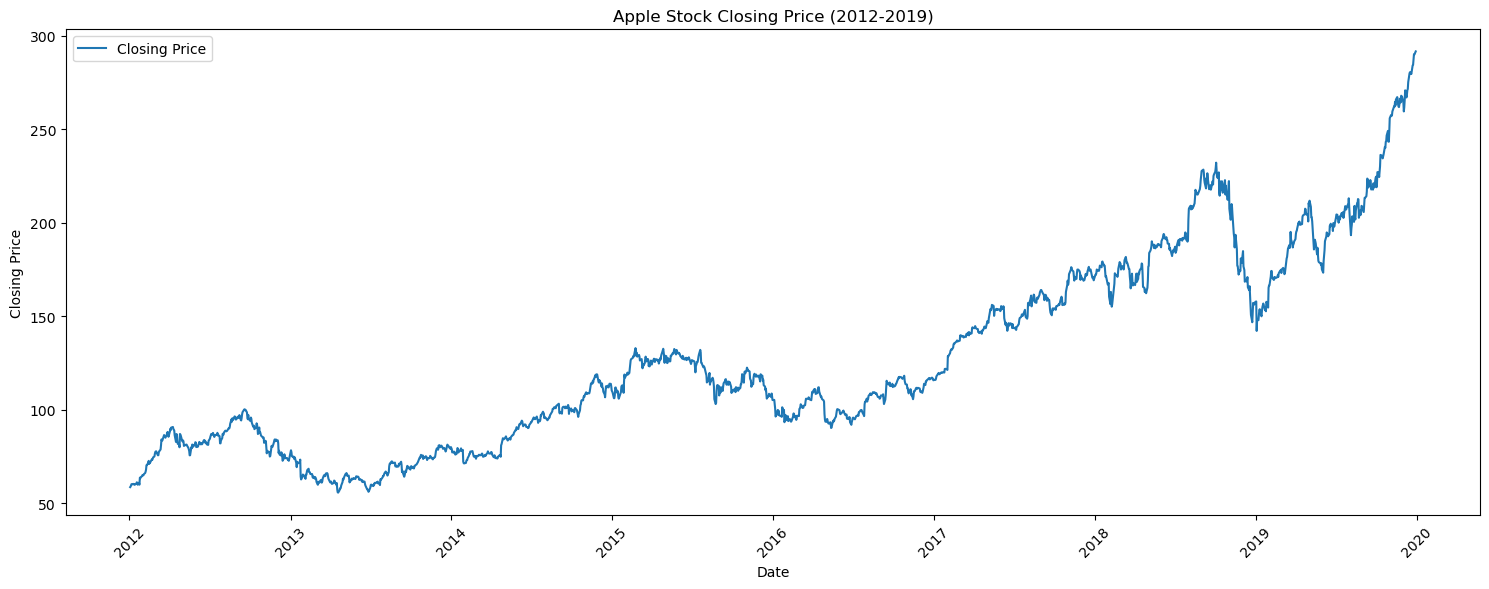

In [19]:
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['Close'], label='Closing Price')
plt.title('Apple Stock Closing Price (2012-2019)')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Apple Stock OHLC Price Analysis

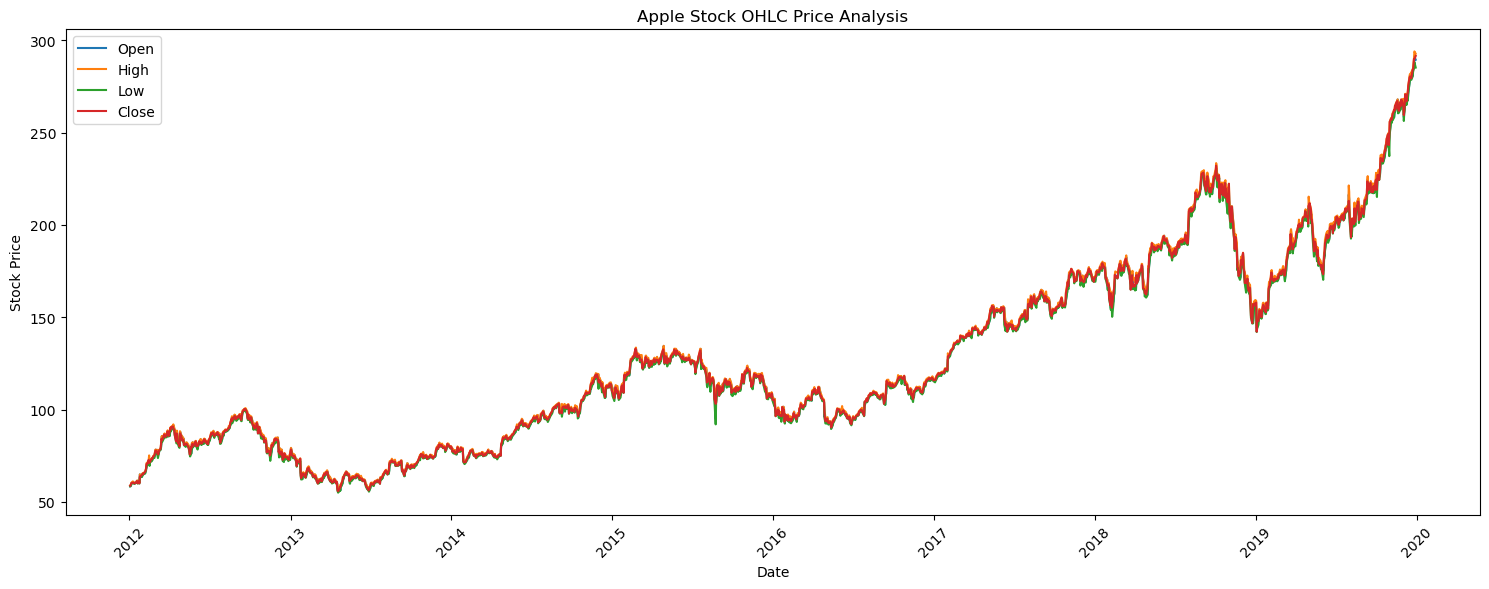

In [20]:
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['Open'], label='Open')
plt.plot(df.index, df['High'], label='High')
plt.plot(df.index, df['Low'], label='Low')
plt.plot(df.index, df['Close'], label='Close')
plt.title('Apple Stock OHLC Price Analysis')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Apple Stock Trading Volume Visualization

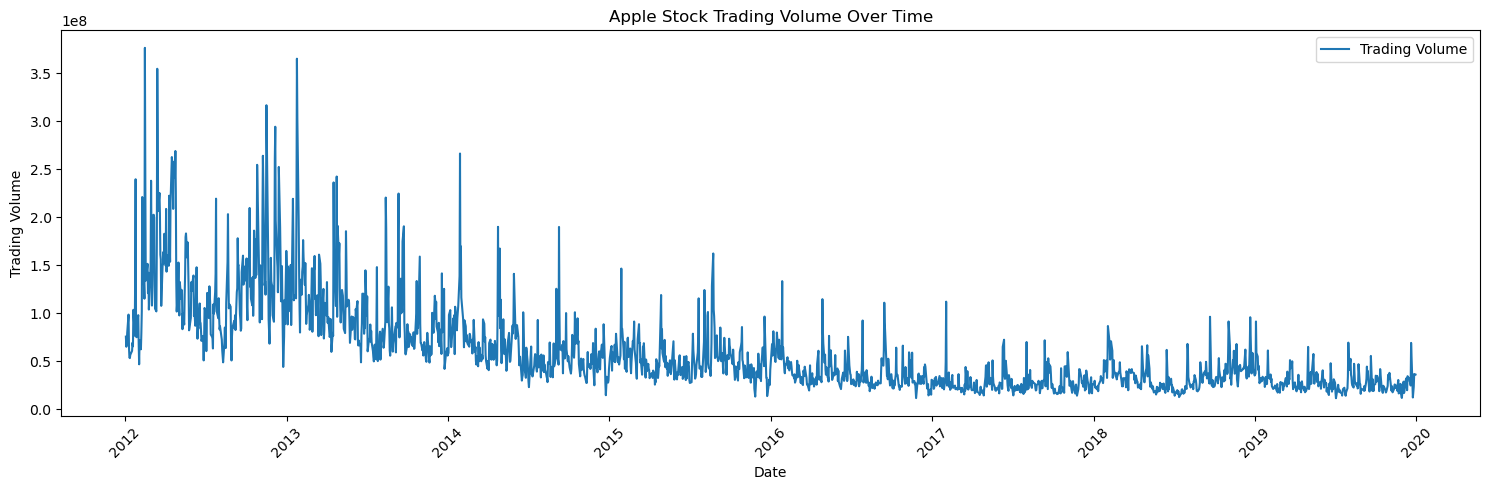

In [21]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['Volume'], label='Trading Volume')
plt.title('Apple Stock Trading Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Trading Volume')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Distribution of Closing Prices Visualization

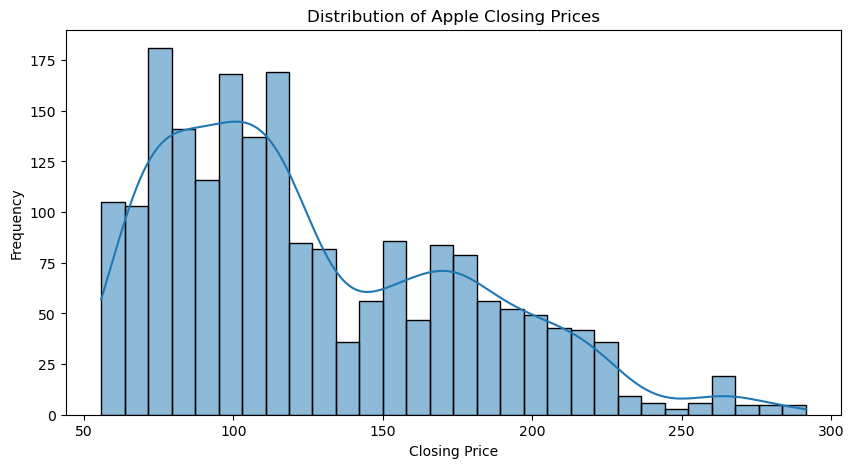

In [22]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Close'], bins=30, kde=True)
plt.title('Distribution of Apple Closing Prices')
plt.xlabel('Closing Price')
plt.ylabel('Frequency')
plt.show()

### Monthly Average Closing Price Visualization

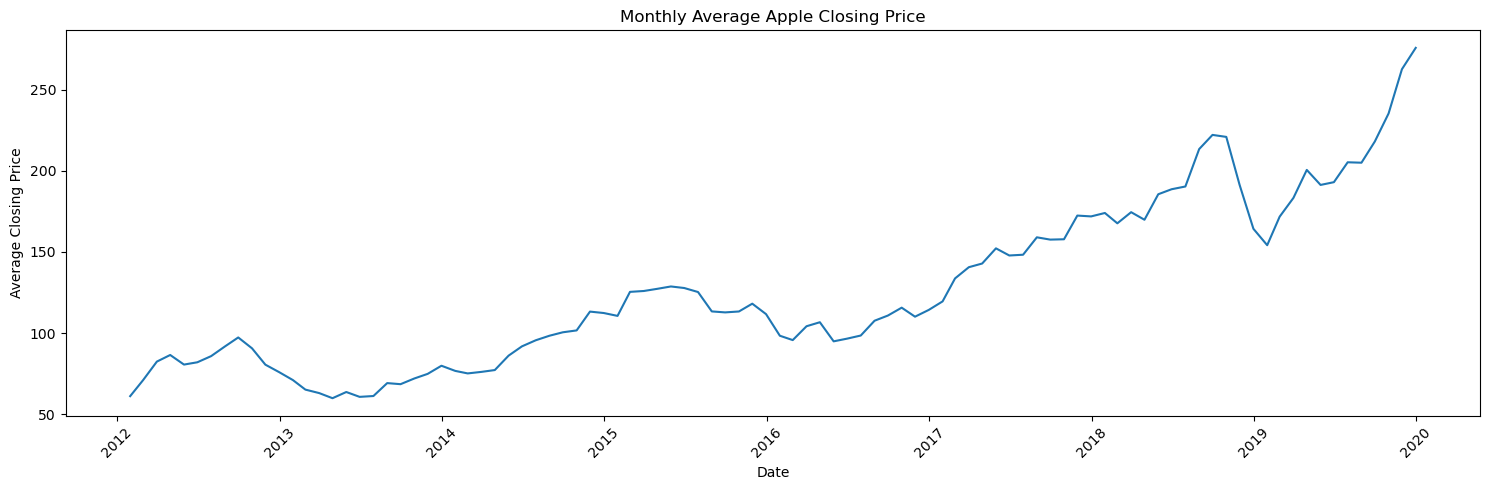

In [23]:
monthly_close = df['Close'].resample('ME').mean()
plt.figure(figsize=(15, 5))
plt.plot(monthly_close.index, monthly_close)
plt.title('Monthly Average Apple Closing Price')
plt.xlabel('Date')
plt.ylabel('Average Closing Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Yearly Average Closing Price Visualization

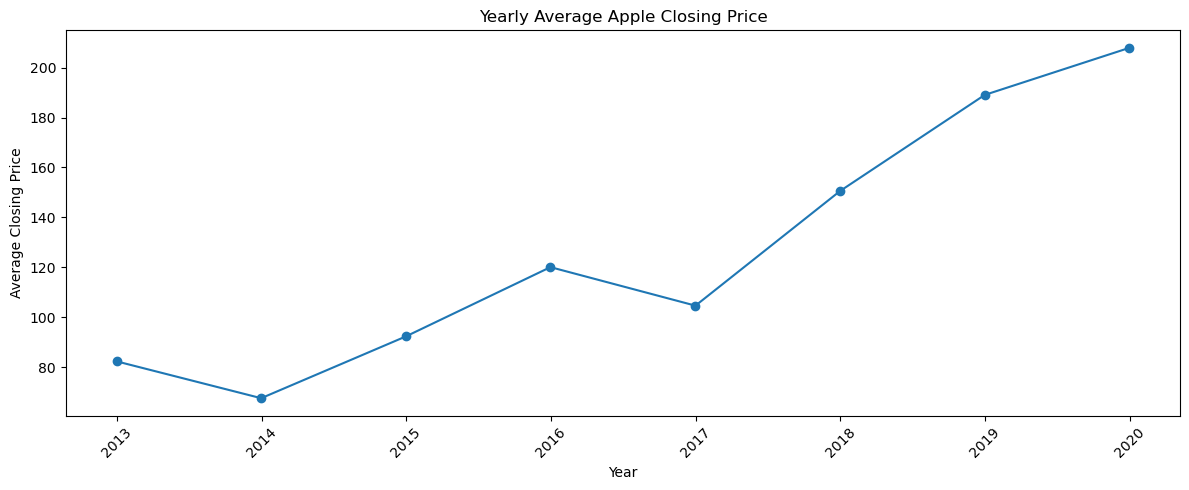

In [24]:
yearly_close = df['Close'].resample('YE').mean()
plt.figure(figsize=(12, 5))
plt.plot(yearly_close.index, yearly_close, marker='o')
plt.title('Yearly Average Apple Closing Price')
plt.xlabel('Year')
plt.ylabel('Average Closing Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Daily Stock Return Visualization

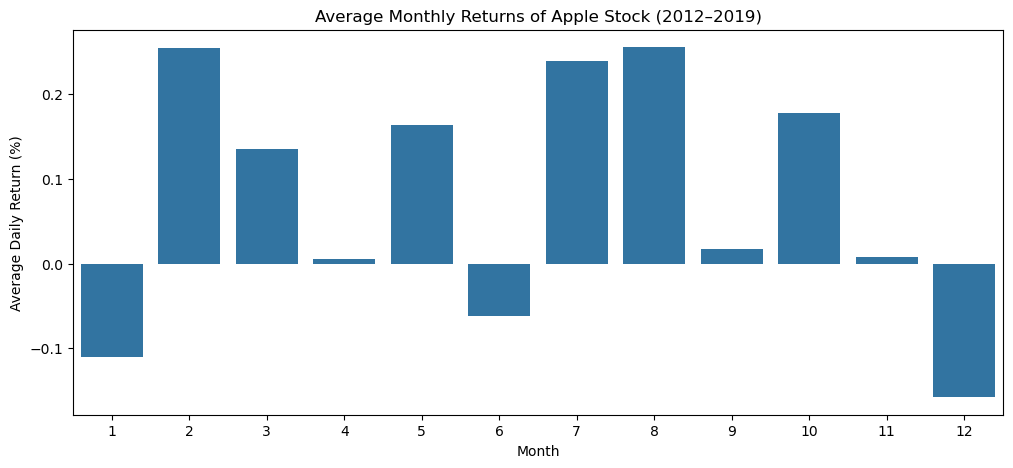

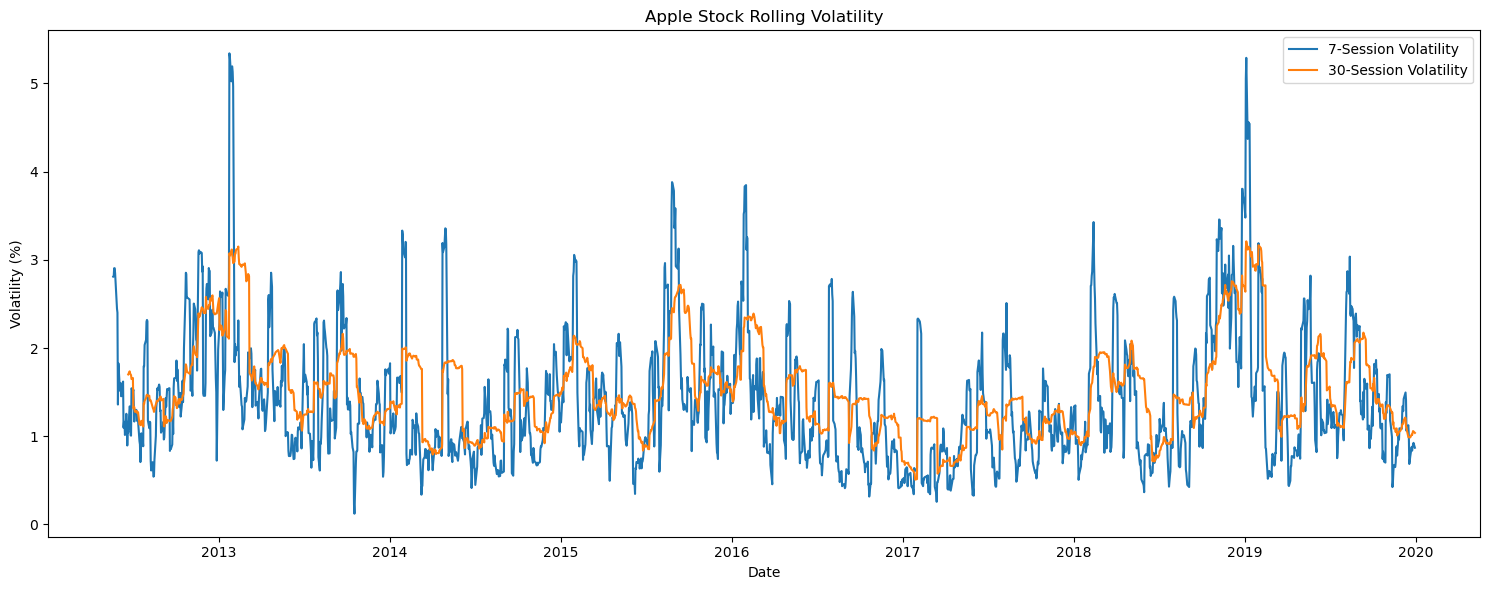

In [55]:
# Calculate daily percentage returns consistently
df['Daily_Return_Pct'] = df['Close'].pct_change() * 100

# Monthly seasonality analysis
df['Month'] = df.index.month
df['Year'] = df.index.year

monthly_returns = (
    df.groupby('Month')['Daily_Return_Pct']
      .mean()
)

plt.figure(figsize=(12, 5))
sns.barplot(
    x=monthly_returns.index,
    y=monthly_returns.values
)
plt.title('Average Monthly Returns of Apple Stock (2012–2019)')
plt.xlabel('Month')
plt.ylabel('Average Daily Return (%)')
plt.show()

# Rolling volatility using percentage returns
df['Volatility_7'] = (
    df['Daily_Return_Pct'].rolling(window=7).std()
)

df['Volatility_30'] = (
    df['Daily_Return_Pct'].rolling(window=30).std()
)

plt.figure(figsize=(15, 6))
plt.plot(df.index, df['Volatility_7'], label='7-Session Volatility')
plt.plot(df.index, df['Volatility_30'], label='30-Session Volatility')

plt.title('Apple Stock Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Volatility (%)')
plt.legend()
plt.tight_layout()
plt.show()

### External Events Analysis Visualization

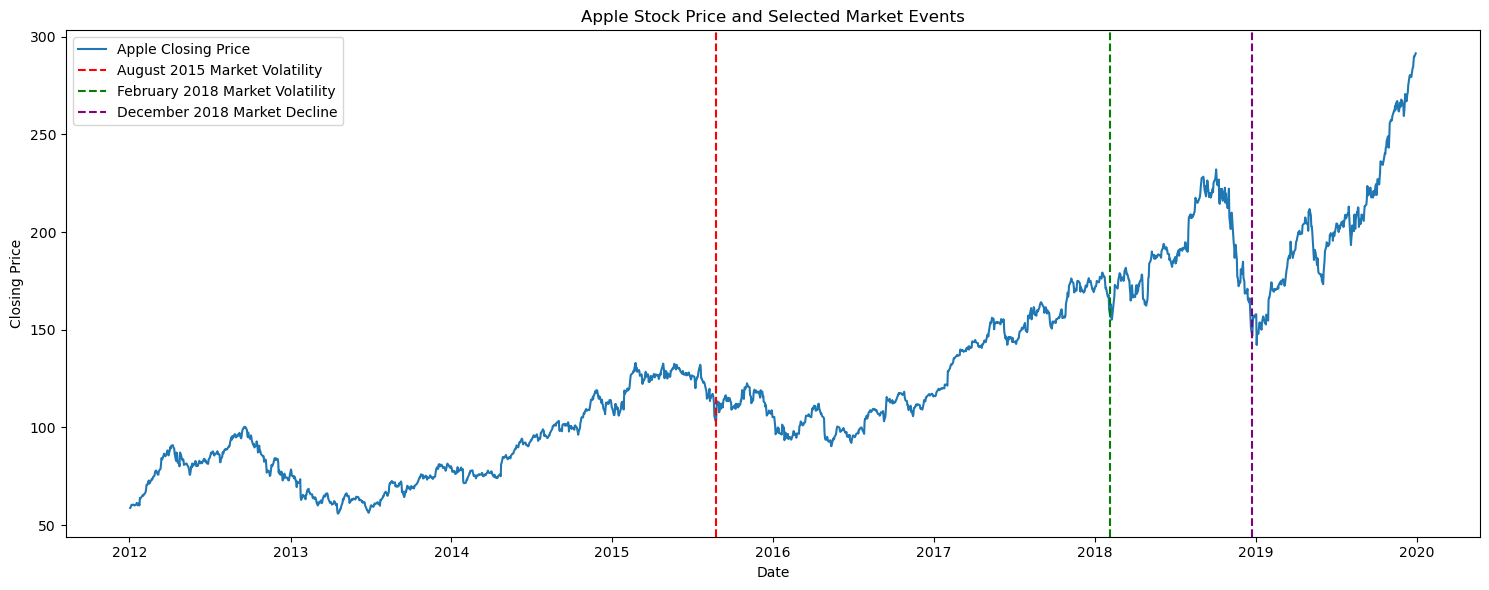

In [28]:
plt.figure(figsize=(15,6))
plt.plot(df.index,df['Close'],label='Apple Closing Price')
plt.axvline(pd.Timestamp('2015-08-24'),
            color='red',
            linestyle='--',
            label='August 2015 Market Volatility')
plt.axvline(pd.Timestamp('2018-02-05'),
            color='green',
            linestyle='--',
            label='February 2018 Market Volatility')
plt.axvline(pd.Timestamp('2018-12-24'),
            color='purple',
            linestyle='--',
            label='December 2018 Market Decline')
plt.title('Apple Stock Price and Selected Market Events')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.tight_layout()
plt.show()

### Correlation Heatmap

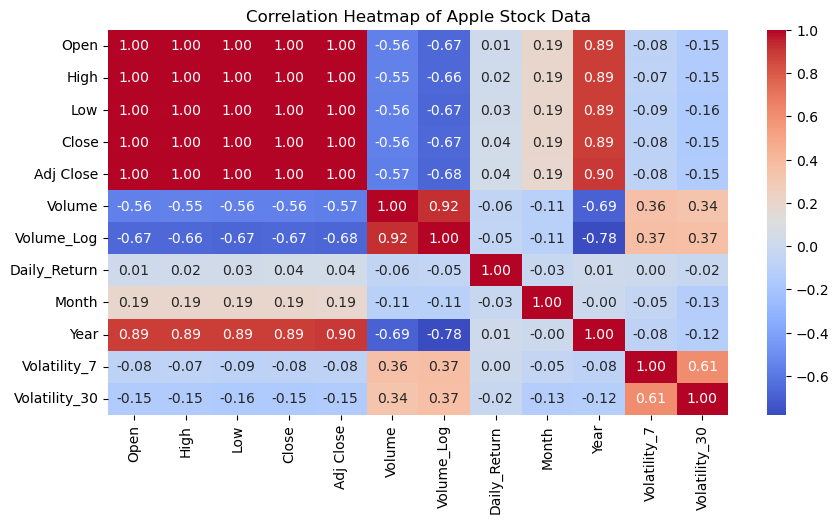

In [29]:
numeric_cols = df.select_dtypes(include=np.number).columns
correlation = df[numeric_cols].corr()
plt.figure(figsize=(10, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap of Apple Stock Data')
plt.show()

# Feature Engineering

In [30]:
#Extracting Date Based Features
df['Year']=df.index.year

df['Month']=df.index.month

df['Day']=df.index.day

df['Day_of_Week']=df.index.dayofweek

df['Quarter']=df.index.quarter

df[['Year','Month', 'Day', 'Day_of_Week', 'Quarter']].head()

,Year,Month,Day,Day_of_Week,Quarter
Date,,,,,
2012-01-03,2012,1,3,1,1
2012-01-04,2012,1,4,2,1
2012-01-05,2012,1,5,3,1
2012-01-06,2012,1,6,4,1
2012-01-09,2012,1,9,0,1


In [31]:
df[['Year','Month', 'Day', 'Day_of_Week', 'Quarter']].tail()

,Year,Month,Day,Day_of_Week,Quarter
Date,,,,,
2019-12-23,2019,12,23,0,4
2019-12-24,2019,12,24,1,4
2019-12-26,2019,12,26,3,4
2019-12-27,2019,12,27,4,4
2019-12-30,2019,12,30,0,4


In [32]:
df['Price_Range']=df['High']-df['Low']
df[['High','Low', 'Price_Range']].head()

,High,Low,Price_Range
Date,,,
2012-01-03,58.928570,58.428570,0.500000
2012-01-04,59.240002,58.468571,0.771431
2012-01-05,59.792858,58.952858,0.840000
2012-01-06,60.392857,59.888573,0.504284
2012-01-09,61.107143,60.192856,0.914287


In [33]:
df['Price_change']=df['Close']-df['Open']
df[['Open','Close','Price_change']].head()

,Open,Close,Price_change
Date,,,
2012-01-03,58.485714,58.747143,0.261429
2012-01-04,58.571430,59.062859,0.491429
2012-01-05,59.278572,59.718571,0.439999
2012-01-06,59.967144,60.342857,0.375713
2012-01-09,60.785713,60.247143,-0.538570


In [34]:
#Display closing price and daily percentage return
df[['Close','Daily_Return']].head(10)

,Close,Daily_Return
Date,,
2012-01-03,58.747143,NaN
2012-01-04,59.062859,0.005374
2012-01-05,59.718571,0.011102
2012-01-06,60.342857,0.010454
2012-01-09,60.247143,-0.001586
2012-01-10,60.462856,0.003580
2012-01-11,60.364285,-0.001630
2012-01-12,60.198570,-0.002745
2012-01-13,59.972858,-0.003749


In [35]:
#Creating Lag Features
#Create previous trading day's closing price
df['Close_Lag_1']=df['Close'].shift(1)

#Create closing price from seven trading observations earlier
df['Close_Lag_7']=df['Close'].shift(7)

#Create closing price from thirty trading observations earlier
df['Close_Lag_30']=df['Close'].shift(30)

#Display original and lag features
df[['Close',
    'Close_Lag_1',
    'Close_Lag_7',
    'Close_Lag_30']].head(35)

,Close,Close_Lag_1,Close_Lag_7,Close_Lag_30
Date,,,,
2012-01-03,58.747143,NaN,NaN,NaN
2012-01-04,59.062859,58.747143,NaN,NaN
2012-01-05,59.718571,59.062859,NaN,NaN
2012-01-06,60.342857,59.718571,NaN,NaN
2012-01-09,60.247143,60.342857,NaN,NaN
2012-01-10,60.462856,60.247143,NaN,NaN
2012-01-11,60.364285,60.462856,NaN,NaN
2012-01-12,60.198570,60.364285,58.747143,NaN
2012-01-13,59.972858,60.198570,59.062859,NaN


In [36]:
#creating moving average features
# Calculate 7-observation moving average
df['MA_7'] = df['Close'].rolling(window=7).mean()

# Calculate 30-observation moving average
df['MA_30'] = df['Close'].rolling(window=30).mean()

# Calculate 90-observation moving average
df['MA_90'] = df['Close'].rolling(window=90).mean()

# Display closing price and moving averages
df[['Close', 'MA_7', 'MA_30', 'MA_90']].tail(10)

,Close,MA_7,MA_30,MA_90
Date,,,,
2019-12-16,279.859985,271.907139,264.962334,236.444334
2019-12-17,280.410004,273.292855,265.726001,237.326778
2019-12-18,279.739990,275.124281,266.479667,238.207445
2019-12-19,280.019989,276.772849,267.239000,238.996889
2019-12-20,279.440002,278.011422,267.906001,239.849000
2019-12-23,284.000000,279.802852,268.701334,240.763000
2019-12-24,284.269989,281.105708,269.436999,241.627111
2019-12-26,289.910004,282.541425,270.368667,242.511111
2019-12-27,289.799988,283.882852,271.212999,243.393777


In [37]:
#creating volume based features
# Apply logarithmic transformation to trading volume
df['Volume_Log'] = np.log1p(df['Volume'])

# Calculate percentage change in trading volume
df['Volume_Change'] = df['Volume'].pct_change() * 100

# Display original and engineered volume features
df[['Volume',
    'Volume_Log',
    'Volume_Change']].head(10)

,Volume,Volume_Log,Volume_Change
Date,,,
2012-01-03,75555200,18.140374,NaN
2012-01-04,65005500,17.989982,-13.962904
2012-01-05,67817400,18.032329,4.325634
2012-01-06,79573200,18.192188,17.334489
2012-01-09,98506100,18.405629,23.793061
2012-01-10,64549100,17.982937,-34.471977
2012-01-11,53771200,17.800249,-16.697212
2012-01-12,53146800,17.788568,-1.161216
2012-01-13,56505400,17.849847,6.319477


In [38]:
#checking all engineered features
# Display total number of columns
print("Total Columns After Feature Engineering:", df.shape[1])

# Display all column names
print("\nAll Features:")
print(df.columns.tolist())

# Display first five records
display(df.head())

# Display dataset information
df.info()

Total Columns After Feature Engineering: 24

All Features:
['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Volume_Log', 'Daily_Return', 'Month', 'Year', 'Volatility_7', 'Volatility_30', 'Day', 'Day_of_Week', 'Quarter', 'Price_Range', 'Price_change', 'Close_Lag_1', 'Close_Lag_7', 'Close_Lag_30', 'MA_7', 'MA_30', 'MA_90', 'Volume_Change']


,Open,High,Low,Close,Adj Close,Volume,Volume_Log,Daily_Return,Month,Year,...,Quarter,Price_Range,Price_change,Close_Lag_1,Close_Lag_7,Close_Lag_30,MA_7,MA_30,MA_90,Volume_Change
Date,,,,,,,,,,,,,,,,,,,,,
2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200,18.140374,NaN,1,2012,...,1,0.500000,0.261429,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500,17.989982,0.005374,1,2012,...,1,0.771431,0.491429,58.747143,NaN,NaN,NaN,NaN,NaN,-13.962904
2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400,18.032329,0.011102,1,2012,...,1,0.840000,0.439999,59.062859,NaN,NaN,NaN,NaN,NaN,4.325634
2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200,18.192188,0.010454,1,2012,...,1,0.504284,0.375713,59.718571,NaN,NaN,NaN,NaN,NaN,17.334489
2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100,18.405629,-0.001586,1,2012,...,1,0.914287,-0.538570,60.342857,NaN,NaN,NaN,NaN,NaN,23.793061


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2011 entries, 2012-01-03 to 2019-12-30
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Open           2011 non-null   float64
 1   High           2011 non-null   float64
 2   Low            2011 non-null   float64
 3   Close          2011 non-null   float64
 4   Adj Close      2011 non-null   float64
 5   Volume         2011 non-null   int64  
 6   Volume_Log     2011 non-null   float64
 7   Daily_Return   2010 non-null   float64
 8   Month          2011 non-null   int32  
 9   Year           2011 non-null   int32  
 10  Volatility_7   2004 non-null   float64
 11  Volatility_30  1981 non-null   float64
 12  Day            2011 non-null   int32  
 13  Day_of_Week    2011 non-null   int32  
 14  Quarter        2011 non-null   int32  
 15  Price_Range    2011 non-null   float64
 16  Price_change   2011 non-null   float64
 17  Close_Lag_1    2010 non-null   flo

In [39]:
# Check missing values in all columns
print("Missing Values After Feature Engineering:")

print(df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:")

print(df.isnull().sum().sum())

Missing Values After Feature Engineering:
Open              0
High              0
Low               0
Close             0
Adj Close         0
Volume            0
Volume_Log        0
Daily_Return      1
Month             0
Year              0
Volatility_7      7
Volatility_30    30
Day               0
Day_of_Week       0
Quarter           0
Price_Range       0
Price_change      0
Close_Lag_1       1
Close_Lag_7       7
Close_Lag_30     30
MA_7              6
MA_30            29
MA_90            89
Volume_Change     1
dtype: int64

Total Missing Values:
201


In [40]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

Dataset Shape: (2011, 24)


In [41]:
# Count missing values in each column
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Open              0
High              0
Low               0
Close             0
Adj Close         0
Volume            0
Volume_Log        0
Daily_Return      1
Month             0
Year              0
Volatility_7      7
Volatility_30    30
Day               0
Day_of_Week       0
Quarter           0
Price_Range       0
Price_change      0
Close_Lag_1       1
Close_Lag_7       7
Close_Lag_30     30
MA_7              6
MA_30            29
MA_90            89
Volume_Change     1
dtype: int64


In [42]:
# Create a copy of the dataset
df_final = df.copy()

# Remove rows containing missing values
df_final.dropna(inplace=True)

# Check the updated shape
print("Shape after removing missing values:", df_final.shape)

Shape after removing missing values: (1922, 24)


In [43]:
# Check missing values after cleaning
print("Missing Values After Cleaning:")
print(df_final.isnull().sum())

# Check whether any missing values remain
print("Total Missing Values:", df_final.isnull().sum().sum())

Missing Values After Cleaning:
Open             0
High             0
Low              0
Close            0
Adj Close        0
Volume           0
Volume_Log       0
Daily_Return     0
Month            0
Year             0
Volatility_7     0
Volatility_30    0
Day              0
Day_of_Week      0
Quarter          0
Price_Range      0
Price_change     0
Close_Lag_1      0
Close_Lag_7      0
Close_Lag_30     0
MA_7             0
MA_30            0
MA_90            0
Volume_Change    0
dtype: int64
Total Missing Values: 0


In [44]:
# Display the first five rows
display(df_final.head())

# Display the last five rows
display(df_final.tail())

,Open,High,Low,Close,Adj Close,Volume,Volume_Log,Daily_Return,Month,Year,...,Quarter,Price_Range,Price_change,Close_Lag_1,Close_Lag_7,Close_Lag_30,MA_7,MA_30,MA_90,Volume_Change
Date,,,,,,,,,,,,,,,,,,,,,
2012-05-10,82.082855,82.268570,81.205711,81.502853,70.429832,83300000,18.237959,0.002354,5,2012,...,2,1.062859,-0.580002,81.311432,83.161430,88.231430,81.845101,85.342905,76.096429,-30.684995
2012-05-11,80.714287,82.067146,80.621429,80.958572,69.959488,99886500,18.419545,-0.006678,5,2012,...,2,1.445717,0.244285,81.502853,83.711426,87.122856,81.451837,85.137428,76.343222,19.911765
2012-05-14,80.367142,81.072861,79.657143,79.745712,68.911415,88156600,18.294625,-0.014981,5,2012,...,2,1.415718,-0.621430,80.958572,83.117142,85.650002,80.970204,84.940619,76.573032,-11.743229
2012-05-15,80.207146,80.459999,78.821426,79.024284,68.287987,119084000,18.595340,-0.009047,5,2012,...,2,1.638573,-1.182862,79.745712,80.750000,88.375717,80.723673,84.628904,76.787540,35.082342
2012-05-16,79.150002,79.555717,77.291428,78.011429,67.412743,140224000,18.758752,-0.012817,5,2012,...,2,2.264289,-1.138573,79.024284,81.354286,89.902855,80.246122,84.232523,76.983857,17.752175


,Open,High,Low,Close,Adj Close,Volume,Volume_Log,Daily_Return,Month,Year,...,Quarter,Price_Range,Price_change,Close_Lag_1,Close_Lag_7,Close_Lag_30,MA_7,MA_30,MA_90,Volume_Change
Date,,,,,,,,,,,,,,,,,,,,,
2019-12-23,280.529999,284.250000,280.369995,284.000000,282.054138,24643000,17.020003,0.016318,12,2019,...,4,3.880005,3.470001,279.440002,271.459991,260.140015,279.802852,268.701334,240.763000,-64.282660
2019-12-24,284.690002,284.890015,282.920013,284.269989,282.322266,12119700,16.310343,0.000951,12,2019,...,4,1.970002,-0.420013,284.000000,275.149994,262.200012,281.105708,269.436999,241.627111,-50.818894
2019-12-26,284.820007,289.980011,284.700012,289.910004,287.923645,23280300,16.963118,0.019840,12,2019,...,4,5.279999,5.089997,284.269989,279.859985,261.959991,282.541425,270.368667,242.511111,92.086438
2019-12-27,291.119995,293.970001,288.119995,289.799988,287.814392,36566500,17.414643,-0.000379,12,2019,...,4,5.850006,-1.320007,289.910004,280.410004,264.470001,283.882852,271.212999,243.393777,57.070570
2019-12-30,289.459991,292.690002,285.220001,291.519989,289.522614,36028600,17.399824,0.005935,12,2019,...,4,7.470001,2.059998,289.799988,279.739990,262.640015,285.565709,272.175665,244.270222,-1.471019


In [45]:
# Display final dataset information
df_final.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1922 entries, 2012-05-10 to 2019-12-30
Data columns (total 24 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Open           1922 non-null   float64
 1   High           1922 non-null   float64
 2   Low            1922 non-null   float64
 3   Close          1922 non-null   float64
 4   Adj Close      1922 non-null   float64
 5   Volume         1922 non-null   int64  
 6   Volume_Log     1922 non-null   float64
 7   Daily_Return   1922 non-null   float64
 8   Month          1922 non-null   int32  
 9   Year           1922 non-null   int32  
 10  Volatility_7   1922 non-null   float64
 11  Volatility_30  1922 non-null   float64
 12  Day            1922 non-null   int32  
 13  Day_of_Week    1922 non-null   int32  
 14  Quarter        1922 non-null   int32  
 15  Price_Range    1922 non-null   float64
 16  Price_change   1922 non-null   float64
 17  Close_Lag_1    1922 non-null   flo

In [46]:
# Save the final processed dataset
df_final.to_csv("Apple_Stock_Feature_Engineered.csv")

print("Final processed dataset saved successfully!")

Final processed dataset saved successfully!


## Step 1: Data Loading & Chronological 80/20 Split

This step loads the processed dataset, sorts observations by date, removes duplicate dates, and creates an **80% training / 20% testing** split in chronological order. The latest 20% is held out for final evaluation; no random shuffling is used.


In [56]:
import pandas as pd
import numpy as np

# Load the cleaned and feature-engineered dataset
# Run the feature-engineering cells above first.
df = pd.read_csv("Apple_Stock_Feature_Engineered.csv")
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = (df.dropna(subset=['Date'])
        .sort_values('Date')
        .drop_duplicates(subset='Date')
        .set_index('Date'))

if df['Close'].isnull().any():
    raise ValueError("Close contains missing values.")
if (df['Close'] <= 0).any():
    raise ValueError("Close must contain positive prices.")

# Chronological 80/20 train-test split
n = len(df)
train_end = int(n * 0.80)
train_data = df.iloc[:train_end].copy()
test_data = df.iloc[train_end:].copy()

print(f"Training observations: {len(train_data)} ({len(train_data)/n:.1%})")
print(f"Testing observations: {len(test_data)} ({len(test_data)/n:.1%})")
print("Training period:", train_data.index.min(), "to", train_data.index.max())
print("Testing period:", test_data.index.min(), "to", test_data.index.max())


Training observations: 1345
Validation observations: 288
Testing observations: 289

Training period: 2012-05-10 00:00:00 to 2017-09-13 00:00:00
Validation period: 2017-09-14 00:00:00 to 2018-11-02 00:00:00
Testing period: 2018-11-05 00:00:00 to 2019-12-30 00:00:00


Step 2: Naive Baseline Model


What this cell does: Establishes a naive baseline ("persistence model") where tomorrow's price is predicted to equal today's closing price. This provides a fundamental benchmark to ensure that advanced statistical and deep learning models add genuine predictive value.



In [59]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
import numpy as np
import pandas as pd

# Naive Baseline Model
# Predict the next closing price using the previous actual closing price.

baseline_preds = test_data['Close'].shift(1)

baseline_preds.iloc[0] = train_data['Close'].iloc[-1]

# Previous actual closing price for each test observation
previous_actual_close = df['Close'].shift(1).loc[test_data.index]


# Evaluation Metrics Function
def calculate_metrics(y_true, y_pred, previous_close=None):

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    # RMSE
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # MAE
    mae = mean_absolute_error(y_true, y_pred)

    # MAPE
    mape = np.mean(
        np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1e-8))
    ) * 100

    # R-squared
    r2 = r2_score(y_true, y_pred)

    # Directional Accuracy
    if previous_close is None:
        previous_close = pd.Series(y_true).shift(1).to_numpy()
    else:
        previous_close = np.asarray(previous_close, dtype=float)

    valid = np.isfinite(previous_close)

    actual_direction = np.sign(
        y_true[valid] - previous_close[valid]
    )

    predicted_direction = np.sign(
        y_pred[valid] - previous_close[valid]
    )

    directional_accuracy = (
        np.mean(actual_direction == predicted_direction) * 100
    )

    return {
        'RMSE': rmse,
        'MAE': mae,
        'MAPE': mape,
        'R2': r2,
        'Dir_Acc': directional_accuracy
    }


# Calculate Naive Baseline Metrics
baseline_metrics = calculate_metrics(
    test_data['Close'],
    baseline_preds,
    previous_actual_close
)

print("Naive Baseline Metrics Computed Successfully!")
print(baseline_metrics)


Naive Baseline Metrics Computed Successfully!
{'RMSE': np.float64(4.2581962001222875), 'MAE': 2.67449834948097, 'MAPE': np.float64(1.360841114197606), 'R2': 0.9843450165959557, 'Dir_Acc': np.float64(0.34602076124567477)}


##### Step 3: ARIMA Model BuildingMarkdown Cell:What this cell does: Conducts an automated grid search for the optimal ARIMA $(p, d, q)$ parameters using the Akaike Information Criterion (AIC) with $d=1$ (determined via stationarity differencing). It then fits the best ARIMA model on the training data and forecasts the test horizon.

In [64]:
from statsmodels.tsa.arima.model import ARIMA
import itertools
import numpy as np
import pandas as pd

# Use actual trading observations with a simple integer index.
# This avoids unsupported date-frequency warnings.
train_close = pd.Series(
    train_data['Close'].to_numpy(dtype=float)
)

# ARIMA grid search
p_values = range(0, 3)
d_values = [1]
q_values = range(0, 3)

best_aic = float('inf')
best_order = None

for param in itertools.product(p_values, d_values, q_values):
    try:
        model = ARIMA(train_close, order=param)
        fitted_model = model.fit()

        if fitted_model.aic < best_aic:
            best_aic = fitted_model.aic
            best_order = param

    except Exception as error:
        print(f"ARIMA {param} skipped: {error}")

if best_order is None:
    raise RuntimeError("No ARIMA model could be fitted.")

print(f"Optimal ARIMA Order: {best_order}")
print(f"Best AIC: {best_aic:.2f}")

# Fit final ARIMA model
arima_model = ARIMA(
    train_close,
    order=best_order
)

arima_fit = arima_model.fit()

# Forecast the test observations
arima_values = arima_fit.forecast(
    steps=len(test_data)
)

# Attach the actual test dates to predictions
arima_preds = pd.Series(
    np.asarray(arima_values),
    index=test_data.index,
    name='ARIMA_Predicted'
)

# Calculate evaluation metrics
arima_metrics = calculate_metrics(
    test_data['Close'],
    arima_preds,
    previous_actual_close
)

print("\nARIMA Model Fitted Successfully!")
print("ARIMA Evaluation Metrics:")
print(arima_metrics)

Optimal ARIMA Order: (0, 1, 0)
Best AIC: 4955.46

ARIMA Model Fitted Successfully!
ARIMA Evaluation Metrics:
{'RMSE': np.float64(55.73355626720727), 'MAE': 45.26696001384084, 'MAPE': np.float64(20.31619117828592), 'R2': -1.6818518718135085, 'Dir_Acc': np.float64(46.36678200692042)}


Step 4: SARIMA Model Building

What this cell does: Fits a Seasonal ARIMA (SARIMA) model incorporating a weekly seasonal period ($s=5$ business days). It builds upon the optimal ARIMA order while capturing recurring weekly seasonal patterns in stock trading behavior.

In [65]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import pandas as pd

# Use actual trading observations with an integer index
train_close = pd.Series(
    train_data['Close'].to_numpy(dtype=float)
)

# Build SARIMA model
sarima_model = SARIMAX(
    train_close,
    order=best_order,
    seasonal_order=(1, 1, 1, 5),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Fit the model
sarima_fit = sarima_model.fit(disp=False)

# Forecast the test period
sarima_values = sarima_fit.forecast(
    steps=len(test_data)
)

# Attach actual test dates to predictions
sarima_preds = pd.Series(
    np.asarray(sarima_values),
    index=test_data.index,
    name='SARIMA_Predicted'
)

# Calculate evaluation metrics
sarima_metrics = calculate_metrics(
    test_data['Close'],
    sarima_preds,
    previous_actual_close
)

print("SARIMA Model Fitted Successfully!")
print("SARIMA Evaluation Metrics:")
print(sarima_metrics)

SARIMA Model Fitted Successfully!
SARIMA Evaluation Metrics:
{'RMSE': np.float64(43.06573761724906), 'MAE': 34.24489605506504, 'MAPE': np.float64(15.330504369936016), 'R2': -0.6012718008918407, 'Dir_Acc': np.float64(46.02076124567474)}


## Step 5: LSTM Neural Network Model

The LSTM uses Close, Volume_Log, MA_7 and MA_30 with a 10-observation look-back. Scaling is fitted only on the chronological 80% training period. The model is trained on training sequences and evaluated on the held-out final 20%; the test period is not used for early stopping or model fitting.


In [66]:
import tensorflow as tf
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)
tf.random.set_seed(42)
features = ['Close', 'Volume_Log', 'MA_7', 'MA_30']
LOOKBACK = 10
train_end = len(train_data)

# Fit preprocessing only on the 80% training period
scaler = MinMaxScaler()
scaler.fit(train_data[features])
scaled_data = scaler.transform(df[features])

X, y, target_positions = [], [], []
for i in range(LOOKBACK, len(scaled_data)):
    X.append(scaled_data[i-LOOKBACK:i, :])
    y.append(scaled_data[i, 0])
    target_positions.append(i)
X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.float32)
target_positions = np.asarray(target_positions)
train_mask = target_positions < train_end
test_mask = target_positions >= train_end
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]
test_dates = df.index[target_positions[test_mask]]
print("Training sequences:", X_train.shape)
print("Testing sequences:", X_test.shape)

lstm_model = Sequential([
    LSTM(50, input_shape=(LOOKBACK, len(features))),
    Dropout(0.2),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')

# Train only on the 80% training sequences; no test-set validation
lstm_history = lstm_model.fit(
    X_train, y_train, epochs=30, batch_size=32,
    shuffle=False, verbose=1
)

lstm_scaled_predictions = lstm_model.predict(X_test, verbose=0).flatten()
lstm_predictions = scaler.inverse_transform(
    np.column_stack([lstm_scaled_predictions,
                    np.zeros((len(lstm_scaled_predictions), len(features)-1))])
)[:, 0]
lstm_predictions_series = pd.Series(lstm_predictions, index=test_dates, name='LSTM_Predicted')
lstm_metrics = calculate_metrics(
    df.loc[test_dates, 'Close'], lstm_predictions_series,
    df['Close'].shift(1).loc[test_dates]
)
print("LSTM evaluation metrics:")
print(lstm_metrics)


Training sequences: (1335, 10, 4)
Validation sequences: (288, 10, 4)
Testing sequences: (289, 10, 4)
Epoch 1/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0280 - val_loss: 0.0212
Epoch 2/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0134 - val_loss: 0.0078
Epoch 3/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0089 - val_loss: 0.0158
Epoch 4/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0077 - val_loss: 0.0057
Epoch 5/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0081 - val_loss: 0.0116
Epoch 6/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0076 - val_loss: 0.0084
Epoch 7/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0089 - val_loss: 0.0119
Epoch 8/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0098 - val_loss: 0.0172
Epoch 9/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0082 - val_loss: 0.0146

LSTM Model Training Completed!
LSTM Evaluation Metrics:
{'RMSE': np.float64(16.81632919925104), 'MAE': 12.705011843877637, 'MAPE': np.floa

## Step 6: GRU Neural Network Model

The GRU follows the same 80/20 chronological split and feature/scaling setup as the LSTM. It is trained only on the first 80% of observations and evaluated on the final 20%.


In [67]:
from tensorflow.keras.layers import GRU
from tensorflow.keras.models import Sequential
import numpy as np
import pandas as pd

np.random.seed(42)
tf.random.set_seed(42)

gru_model = Sequential([
    GRU(50, input_shape=(LOOKBACK, len(features))),
    Dropout(0.2),
    Dense(1)
])
gru_model.compile(optimizer='adam', loss='mse')

gru_history = gru_model.fit(
    X_train, y_train, epochs=30, batch_size=32,
    shuffle=False, verbose=1
)

gru_scaled_predictions = gru_model.predict(X_test, verbose=0).flatten()
gru_predictions = scaler.inverse_transform(
    np.column_stack([gru_scaled_predictions,
                    np.zeros((len(gru_scaled_predictions), len(features)-1))])
)[:, 0]
gru_predictions_series = pd.Series(gru_predictions, index=test_dates, name='GRU_Predicted')
gru_metrics = calculate_metrics(
    df.loc[test_dates, 'Close'], gru_predictions_series,
    df['Close'].shift(1).loc[test_dates]
)
print("GRU evaluation metrics:")
print(gru_metrics)


Epoch 1/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0459 - val_loss: 0.0744
Epoch 2/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0343 - val_loss: 0.0051
Epoch 3/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0061 - val_loss: 0.0072
Epoch 4/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0043 - val_loss: 0.0043
Epoch 5/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0049 - val_loss: 0.0032
Epoch 6/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0048 - val_loss: 0.0029
Epoch 7/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0048 - val_loss: 0.0027
Epoch 8/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0045 - val_loss: 0.0026
Epoch 9/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0045 - val_loss: 0.0026
Epoch 10/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0045 - val_loss: 0.0025
Epoch 11/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0043 - val_loss: 0.0026
Epoch 12/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0046 

Step 7: Dedicated Model Evaluation & Comparison :

What this cell does: Consolidates all model performance metrics (RMSE, MAE, MAPE, $R^2$, and Directional Accuracy) into a clear comparison table. It also generates diagnostic residual plots for the optimal ARIMA model.

FINAL MODEL PERFORMANCE COMPARISON


,RMSE,MAE,MAPE,R2,Dir_Acc
Model,,,,,
GRU,7.0518,5.5805,2.7429,0.9571,47.4048
LSTM,16.8163,12.7050,5.8906,0.7558,45.6747
SARIMA,43.0657,34.2449,15.3305,-0.6013,46.0208
"ARIMA (0, 1, 0)",55.7336,45.2670,20.3162,-1.6819,46.3668


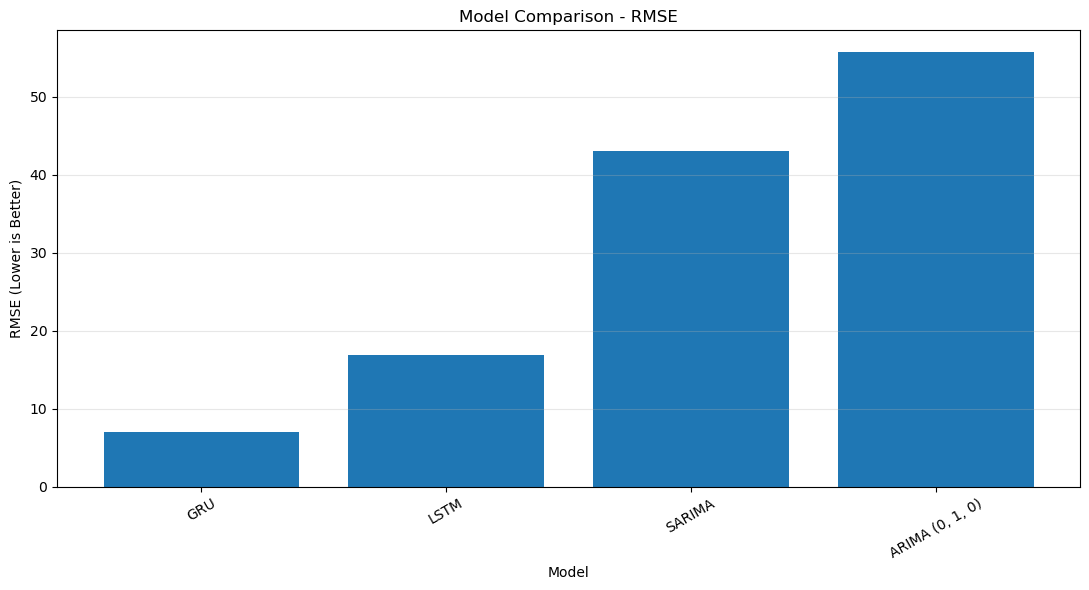

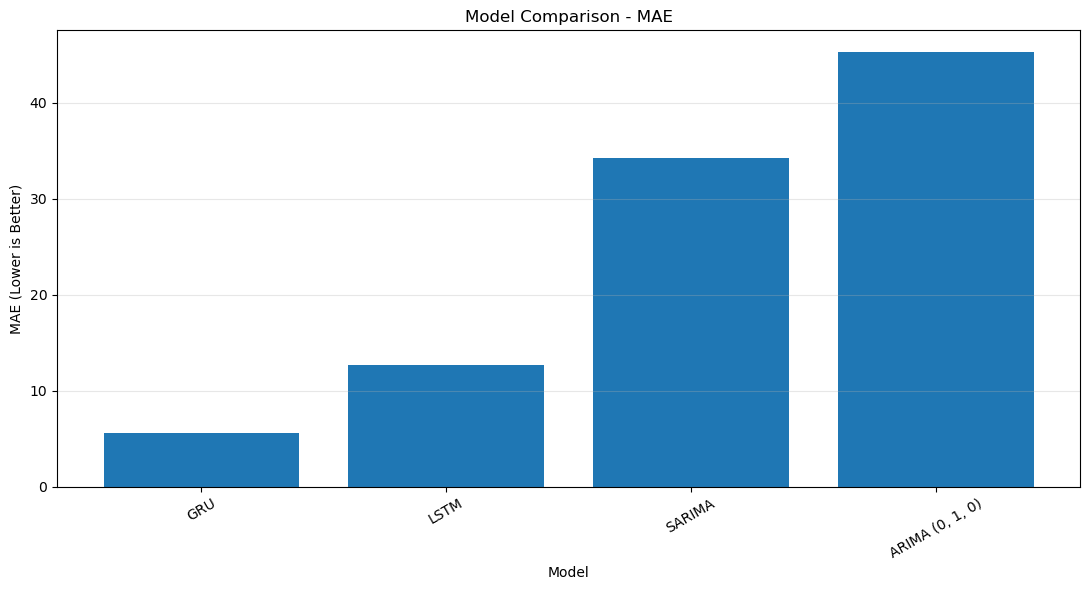

Model evaluation results saved successfully.


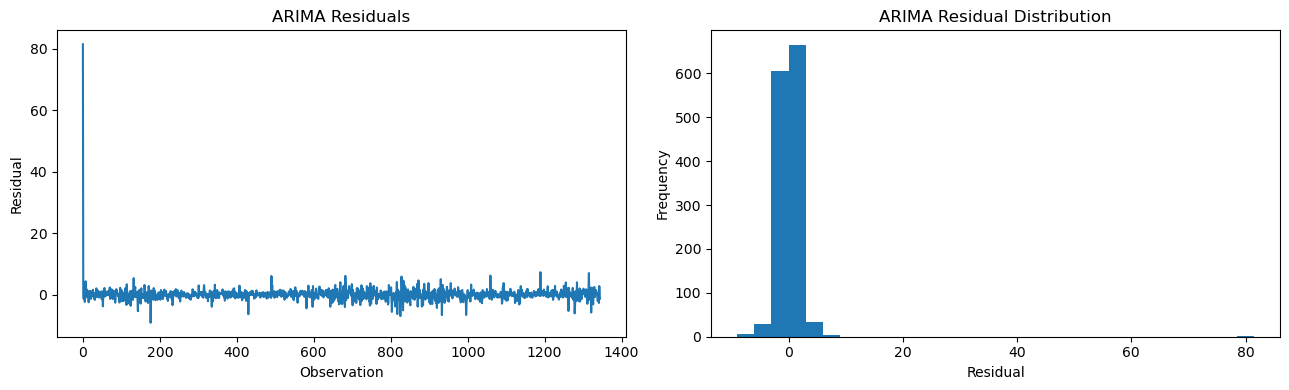

In [73]:
import pandas as pd
import matplotlib.pyplot as plt

# Collect evaluation results from all five models
model_results = {
    f'ARIMA {best_order}': arima_metrics,
    'SARIMA': sarima_metrics,
    'LSTM': lstm_metrics,
    'GRU': gru_metrics
}

# Create comparison table
summary_df = pd.DataFrame(model_results).T

summary_df.index.name = 'Model'

# Sort models by RMSE (lower is better)
summary_df = summary_df.sort_values(
    by='RMSE',
    ascending=True
)

print("FINAL MODEL PERFORMANCE COMPARISON")

display(summary_df.round(4))

# Plot RMSE comparison
plt.figure(figsize=(11, 6))

plt.bar(
    summary_df.index,
    summary_df['RMSE']
)

plt.title('Model Comparison - RMSE')
plt.xlabel('Model')
plt.ylabel('RMSE (Lower is Better)')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Plot MAE comparison
plt.figure(figsize=(11, 6))

plt.bar(
    summary_df.index,
    summary_df['MAE']
)

plt.title('Model Comparison - MAE')
plt.xlabel('Model')
plt.ylabel('MAE (Lower is Better)')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Save evaluation results
summary_df.to_csv(
    'Apple_Model_Evaluation_Results.csv'
)

print("Model evaluation results saved successfully.")

# ARIMA residual diagnostic plots
arima_residuals = pd.Series(
    arima_fit.resid
).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(arima_residuals)
axes[0].set_title('ARIMA Residuals')
axes[0].set_xlabel('Observation')
axes[0].set_ylabel('Residual')

axes[1].hist(arima_residuals, bins=30)
axes[1].set_title('ARIMA Residual Distribution')
axes[1].set_xlabel('Residual')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

Directional Accuracy Highlight


=== MODEL DIRECTIONAL ACCURACY COMPARISON ===
ARIMA: 46.37%
SARIMA: 46.02%
LSTM: 45.67%
GRU: 47.40%

Best directional prediction model:
GRU: 47.40%
Selected forecasting model: SARIMA

APPLE STOCK PRICE - NEXT 30 WEEKDAYS
Selected model: SARIMA


,Date,Predicted_Close,Lower_Confidence,Upper_Confidence
0,2019-12-31,291.75,287.52,295.97
1,2020-01-01,291.74,285.76,297.71
2,2020-01-02,291.82,284.51,299.14
3,2020-01-03,291.93,283.47,300.38
4,2020-01-06,292.07,282.62,301.52
5,2020-01-07,292.30,281.94,302.65
6,2020-01-08,292.28,281.10,303.47
7,2020-01-09,292.37,280.41,304.33
8,2020-01-10,292.47,279.78,305.16
9,2020-01-13,292.61,279.23,305.99


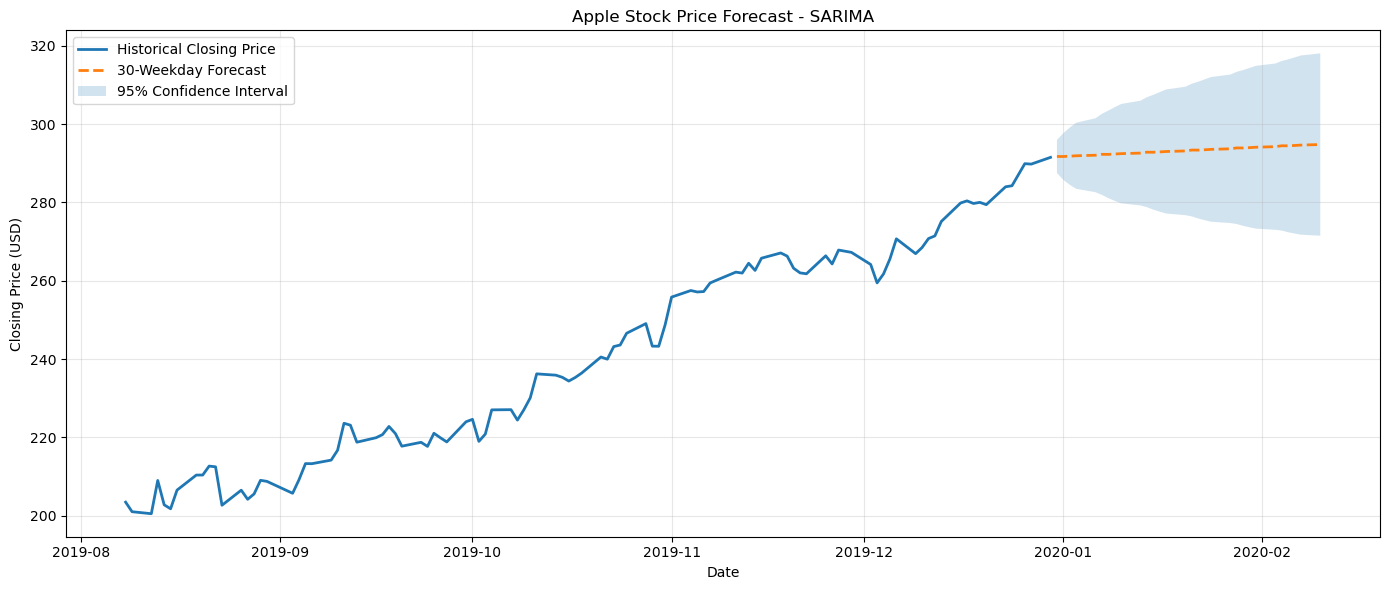


Forecast completed successfully!
Forecast CSV saved successfully.


In [74]:
print("=== MODEL DIRECTIONAL ACCURACY COMPARISON ===")

directional_results = {
    'ARIMA': arima_metrics['Dir_Acc'],
    'SARIMA': sarima_metrics['Dir_Acc'],
    'LSTM': lstm_metrics['Dir_Acc'],
    'GRU': gru_metrics['Dir_Acc']
}

for model, accuracy in directional_results.items():
    print(f"{model}: {accuracy:.2f}%")

best_directional_model = max(
    directional_results,
    key=directional_results.get
)

print("\nBest directional prediction model:")
print(
    f"{best_directional_model}: "
    f"{directional_results[best_directional_model]:.2f}%"
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX


# 1. Select the best statistical model

if arima_metrics['RMSE'] <= sarima_metrics['RMSE']:
    best_model_name = 'ARIMA'
    best_model_order = best_order
else:
    best_model_name = 'SARIMA'
    best_model_order = best_order

print("Selected forecasting model:", best_model_name)

# 2. Prepare complete historical data

close_series = df['Close'].astype(float).reset_index(drop=True)

# 3. Train selected model on all data

if best_model_name == 'ARIMA':

    final_model = ARIMA(
        close_series,
        order=best_model_order
    )

else:

    final_model = SARIMAX(
        close_series,
        order=best_model_order,
        seasonal_order=(1, 1, 1, 5),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

final_fit = final_model.fit()

# 4. Forecast next 30 weekdays

forecast_steps = 30

forecast_result = final_fit.get_forecast(
    steps=forecast_steps
)

forecast_values = np.asarray(
    forecast_result.predicted_mean
)

confidence_intervals = np.asarray(
    forecast_result.conf_int()
)

# Generate future weekday dates
last_date = pd.to_datetime(df.index[-1])

future_dates = pd.bdate_range(
    start=last_date + pd.Timedelta(days=1),
    periods=forecast_steps
)

# 5. Create forecast table

forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Predicted_Close': forecast_values,
    'Lower_Confidence': confidence_intervals[:, 0],
    'Upper_Confidence': confidence_intervals[:, 1]
})

print("\nAPPLE STOCK PRICE - NEXT 30 WEEKDAYS")
print("Selected model:", best_model_name)

display(forecast_df.round(2))

# 6. Plot historical and forecast prices

plt.figure(figsize=(14, 6))

plt.plot(
    df.index[-100:],
    df['Close'].iloc[-100:],
    label='Historical Closing Price',
    linewidth=2
)

plt.plot(
    future_dates,
    forecast_values,
    label='30-Weekday Forecast',
    linestyle='--',
    linewidth=2
)

plt.fill_between(
    future_dates,
    confidence_intervals[:, 0],
    confidence_intervals[:, 1],
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title(
    f'Apple Stock Price Forecast - {best_model_name}'
)

plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Export forecast results

forecast_df.to_csv(
    'Apple_Stock_Next_30_Sessions_Forecast.csv',
    index=False
)

print("\nForecast completed successfully!")
print("Forecast CSV saved successfully.")

Selected forecasting model: SARIMA

APPLE STOCK PRICE - NEXT 30 WEEKDAYS
Selected model: SARIMA


,Date,Predicted_Close,Lower_Confidence,Upper_Confidence
0,2019-12-31,291.75,287.52,295.97
1,2020-01-01,291.74,285.76,297.71
2,2020-01-02,291.82,284.51,299.14
3,2020-01-03,291.93,283.47,300.38
4,2020-01-06,292.07,282.62,301.52
5,2020-01-07,292.30,281.94,302.65
6,2020-01-08,292.28,281.10,303.47
7,2020-01-09,292.37,280.41,304.33
8,2020-01-10,292.47,279.78,305.16
9,2020-01-13,292.61,279.23,305.99


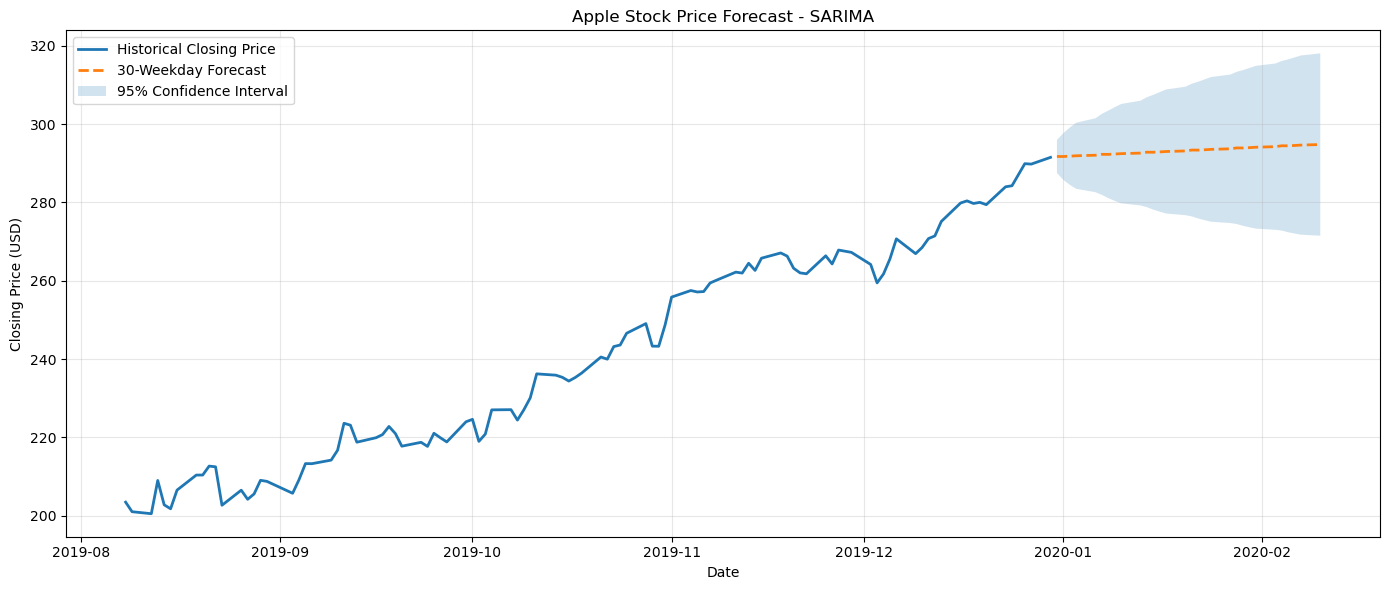


Forecast completed successfully!
Forecast CSV saved successfully.


In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX


# 1. Select the best statistical model


if arima_metrics['RMSE'] <= sarima_metrics['RMSE']:
    best_model_name = 'ARIMA'
    best_model_order = best_order
else:
    best_model_name = 'SARIMA'
    best_model_order = best_order

print("Selected forecasting model:", best_model_name)


# 2. Prepare complete historical data
close_series = df['Close'].astype(float).reset_index(drop=True)


# 3. Train selected model on all data

if best_model_name == 'ARIMA':

    final_model = ARIMA(
        close_series,
        order=best_model_order
    )

else:

    final_model = SARIMAX(
        close_series,
        order=best_model_order,
        seasonal_order=(1, 1, 1, 5),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

final_fit = final_model.fit()

# 4. Forecast next 30 weekdays

forecast_steps = 30

forecast_result = final_fit.get_forecast(
    steps=forecast_steps
)

forecast_values = np.asarray(
    forecast_result.predicted_mean
)

confidence_intervals = np.asarray(
    forecast_result.conf_int()
)

# Generate future weekday dates
last_date = pd.to_datetime(df.index[-1])

future_dates = pd.bdate_range(
    start=last_date + pd.Timedelta(days=1),
    periods=forecast_steps
)

# 5. Create forecast table

forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Predicted_Close': forecast_values,
    'Lower_Confidence': confidence_intervals[:, 0],
    'Upper_Confidence': confidence_intervals[:, 1]
})

print("\nAPPLE STOCK PRICE - NEXT 30 WEEKDAYS")
print("Selected model:", best_model_name)

display(forecast_df.round(2))

# 6. Plot historical and forecast prices

plt.figure(figsize=(14, 6))

plt.plot(
    df.index[-100:],
    df['Close'].iloc[-100:],
    label='Historical Closing Price',
    linewidth=2
)

plt.plot(
    future_dates,
    forecast_values,
    label='30-Weekday Forecast',
    linestyle='--',
    linewidth=2
)

plt.fill_between(
    future_dates,
    confidence_intervals[:, 0],
    confidence_intervals[:, 1],
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title(
    f'Apple Stock Price Forecast - {best_model_name}'
)

plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Export forecast results

forecast_df.to_csv(
    'Apple_Stock_Next_30_Sessions_Forecast.csv',
    index=False
)

print("\nForecast completed successfully!")
print("Forecast CSV saved successfully.")

In [76]:
# FINAL PROJECT SUMMARY

print("=" * 60)
print("       APPLE STOCK PRICE PREDICTION PROJECT")
print("=" * 60)

# 1. Dataset information
print("\n1. DATASET INFORMATION")

print("Total observations:", len(df))
print("First available date:", df.index.min())
print("Last available date:", df.index.max())

# 2. Model comparison
print("\n2. MODEL PERFORMANCE COMPARISON")

display(summary_df.round(4))

# 3. Best model based on RMSE
best_model = summary_df['RMSE'].idxmin()

print("\nBest model based on RMSE:", best_model)
print("Best RMSE:", round(summary_df.loc[best_model, 'RMSE'], 4))

# 4. Directional accuracy
print("\n3. DIRECTIONAL ACCURACY")

for model, accuracy in directional_results.items():
    print(f"{model}: {accuracy:.2f}%")

# 5. Forecast information
print("\n4. FUTURE STOCK FORECAST")

print("Forecasting model:", best_model_name)
print("Forecast horizon:", len(forecast_df), "weekdays")

print(
    "First forecast date:",
    forecast_df['Date'].iloc[0].date()
)

print(
    "Last forecast date:",
    forecast_df['Date'].iloc[-1].date()
)

print(
    "Average forecast closing price:",
    round(forecast_df['Predicted_Close'].mean(), 2)
)

# 6. Save final reports
summary_df.to_csv(
    "Apple_Final_Model_Comparison.csv"
)

forecast_df.to_csv(
    "Apple_Final_Stock_Forecast.csv",
    index=False
)

print("\n5. PROJECT OUTPUTS")

print("Model comparison report saved.")
print("Stock forecast report saved.")

print("\nPROJECT EXECUTION COMPLETED SUCCESSFULLY!")
print("=" * 60)

       APPLE STOCK PRICE PREDICTION PROJECT

1. DATASET INFORMATION
Total observations: 1922
First available date: 2012-05-10 00:00:00
Last available date: 2019-12-30 00:00:00

2. MODEL PERFORMANCE COMPARISON


,RMSE,MAE,MAPE,R2,Dir_Acc
Model,,,,,
GRU,7.0518,5.5805,2.7429,0.9571,47.4048
LSTM,16.8163,12.7050,5.8906,0.7558,45.6747
SARIMA,43.0657,34.2449,15.3305,-0.6013,46.0208
"ARIMA (0, 1, 0)",55.7336,45.2670,20.3162,-1.6819,46.3668



Best model based on RMSE: GRU
Best RMSE: 7.0518

3. DIRECTIONAL ACCURACY
ARIMA: 46.37%
SARIMA: 46.02%
LSTM: 45.67%
GRU: 47.40%

4. FUTURE STOCK FORECAST
Forecasting model: SARIMA
Forecast horizon: 30 weekdays
First forecast date: 2019-12-31
Last forecast date: 2020-02-10
Average forecast closing price: 293.23

5. PROJECT OUTPUTS
Model comparison report saved.
Stock forecast report saved.

PROJECT EXECUTION COMPLETED SUCCESSFULLY!
